# JanaVaani — Department classifier report
Our own trained model (not an LLM call): TF-IDF character + word n-grams → calibrated logistic regression. Evaluated on (1) a **group-split** synthetic test set where no phrase appears in training, and (2) a **hand-written** test set never used for training. All numbers below are read from `ml/models/metrics.json` and recomputed from the saved model.

In [1]:
import json, sys, collections, pathlib
import matplotlib.pyplot as plt
import numpy as np
ROOT = pathlib.Path.cwd().parents[1] if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path[:0] = [str(ROOT / 'ml'), str(ROOT / 'services' / 'api')]
m = json.loads((ROOT / 'ml/models/metrics.json').read_text())
rows = [json.loads(l) for l in (ROOT / 'data/seed/complaints.jsonl').read_text(encoding='utf-8').splitlines() if l.strip()]
print(m['model_version'], m['embedding_model']); print('synthetic acc', m['accuracy'], 'macro-F1', m['macro_f1'], '| human acc', m['human_test']['accuracy'], 'n', m['human_test']['n'])

v20261102-065449 tfidf-char2-5+word1-2
synthetic acc 0.7781 macro-F1 0.7818 | human acc 0.75 n 48


## Dataset distribution

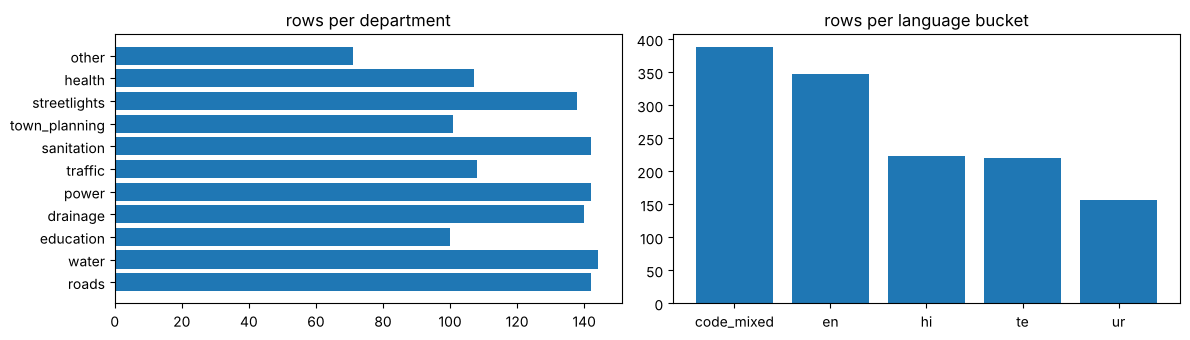

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
c = collections.Counter(r['category'] for r in rows); ax[0].barh(list(c), list(c.values())); ax[0].set_title('rows per department')
l = collections.Counter(r['lang_bucket'] for r in rows); ax[1].bar(list(l), list(l.values())); ax[1].set_title('rows per language bucket'); plt.tight_layout()

## Per-language accuracy (synthetic vs human-written)

Text(0.5, 1.0, 'Accuracy by language')

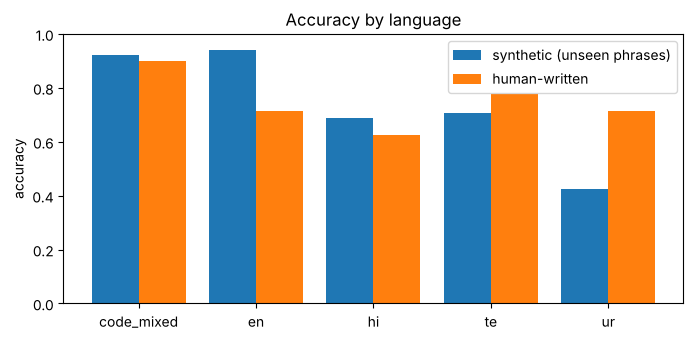

In [3]:
langs = sorted(set(m['per_language']) | set(m['human_test']['per_language']))
x = np.arange(len(langs))
s = [m['per_language'].get(k, {}).get('accuracy', 0) for k in langs]; h = [m['human_test']['per_language'].get(k, {}).get('accuracy', 0) for k in langs]
plt.figure(figsize=(8, 3.5)); plt.bar(x - .2, s, .4, label='synthetic (unseen phrases)'); plt.bar(x + .2, h, .4, label='human-written')
plt.xticks(x, langs); plt.ylim(0, 1); plt.ylabel('accuracy'); plt.legend(); plt.title('Accuracy by language')

## Confusion matrix (synthetic test)

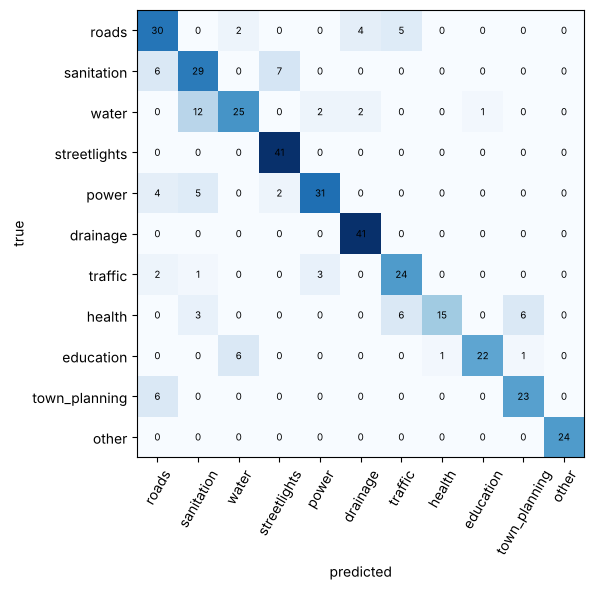

In [4]:
lab = m['confusion']['labels']; cm = np.array(m['confusion']['matrix'])
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap='Blues'); plt.xticks(range(len(lab)), lab, rotation=60); plt.yticks(range(len(lab)), lab)
[plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=7) for i in range(len(lab)) for j in range(len(lab))]; plt.xlabel('predicted'); plt.ylabel('true'); plt.tight_layout()

## Sample predictions

In [5]:
import joblib
model = joblib.load(ROOT / 'ml/models/classifier.joblib')
for t in ['Miyapur X roads lo pedda gunta undi', 'మా వీధిలో మూడు రోజులుగా నీళ్ళు రావడం లేదు', 'गली की स्ट्रीट लाइट खराब है', 'نالی ابل کر سڑک پر آ رہی ہے', 'Transformer near the school is sparking']:
    p = model.predict_proba([t])[0]; i = p.argmax(); print(f'{model.classes_[i]:>13} {p[i]:.2f}  {t}')

        roads 0.94  Miyapur X roads lo pedda gunta undi
        water 0.81  మా వీధిలో మూడు రోజులుగా నీళ్ళు రావడం లేదు
 streetlights 0.88  गली की स्ट्रीट लाइट खराब है
     drainage 0.96  نالی ابل کر سڑک پر آ رہی ہے
        power 0.58  Transformer near the school is sparking


## Human-test errors and retrain history

In [6]:
for e in m['human_test']['errors']: print(f"{e['true']:>13} -> {e['pred']:<13} {e['text'][:70]}")
print('history:', m.get('history', []))

        roads -> traffic       Sir the road near Kukatpally Y junction has become like a pond, two wh
 streetlights -> sanitation    Lamp post number 42 on 3rd cross Madhapur dead for 10 days, very dark
        power -> health        TGSPDCL cut our supply at 9am and still not restored, fridge food spoi
    education -> health        Classroom ceiling plaster fell in ZPHS Alwal, luckily no child was hur
       health -> drainage      Mehdipatnam mein machhar ka aatank hai, har ghar mein bukhar
        water -> drainage      మల్కాజ్‌గిరిలో తాగునీరు రంగు మారి వస్తోంది
town_planning -> health        అక్రమంగా ప్రభుత్వ స్థలంలో షెడ్డు వేశారు
        water -> drainage      हमारे मोहल्ले में नल से बिल्कुल पानी नहीं आ रहा
     drainage -> roads         गटर का ढक्कन टूटा है, कोई भी गिर सकता है
   sanitation -> roads         फलकनुमा में सड़क पर कचरे का ढेर लगा है
        water -> drainage      نلوں میں گدلا پانی آ رہا ہے، بچے بیمار ہو گئے
       health -> sanitation    اسپتال میں صفائی نہیں ہے او

## Limitations
- Training data is template-generated from hand-written phrase banks (no LLM key was available); synthetic accuracy is optimistic.
- The 48-row human test set is small; per-language numbers are indicative. Replace with the team's own complaints.
- Urdu is the weakest language. Semantic embeddings (e5/LaBSE benchmark via `train_classifier.py --features benchmark`) were not runnable in the build sandbox.